<h1>Rock, Paper, Scissors – CNN Image Classification</h1>

<h2>1. Business understanding</h2>

   - The goal of this project is to develop a convolutional neural network (CNN) that can classify images into three categories: rock, paper, and scissors.
   - The dataset consists of our own collected images. The aim is to train and evaluate a model that can recognize these hand gestures from images.

<h2>2. Data understanding</h2>

   - The dataset consists of 297 images collected by our team, divided into three classes: rock, paper, and scissors.
   - The images contain different hand positions and backgrounds to introduce variation into the dataset.
   - The dataset was inspected to ensure that the images were correctly labeled and suitable for training a CNN model.

In [40]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.utils import image_dataset_from_directory

rps_dir = pathlib.Path("./rps") #directory with all data

In [41]:
import tensorflow as tf
print(tf.__version__)
print(tf.config.list_physical_devices())

2.21.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [42]:
#SUPPORTS FORMATS: JPEG (.jpg, .jpeg), PNG (.png), BMP (.bmp) AND GIF (.gif)

train_dataset = image_dataset_from_directory(
    rps_dir / "train",
    image_size = (180, 180),
    batch_size = 32)

validation_dataset = image_dataset_from_directory(
    rps_dir / "validation",
    image_size = (180, 180),
    batch_size = 32)

test_dataset = image_dataset_from_directory(
    rps_dir / "test",
    image_size = (180, 180),
    batch_size = 32)

Found 191 files belonging to 3 classes.
Found 53 files belonging to 3 classes.
Found 53 files belonging to 3 classes.


In [91]:
for name, dataset in [
    ("Training", train_dataset),
    ("Validation", validation_dataset)
]:
    counts = Counter()

    for images, labels in dataset:
        counts.update(labels.numpy().tolist())

    print(name)
    for i, class_name in enumerate(class_names):
        print(class_name, ":", counts[i])
    print()

Training
paper : 63
rock : 64
scissors : 64

Validation
paper : 18
rock : 17
scissors : 18



This code checks how many images each class has in the training and validation datasets. The results show that the images are almost equally divided between the three classes. This is important because the model needs to learn all three classes equally.

<h2>3. Data preparation</h2>

   - All collected images were resized to 180 × 180 pixels to ensure a consistent input size for the CNN model.
   - Pixel values were normalized to the range [0, 1] to improve the training process.
   - The dataset was divided into training, validation, and testing.
   - Data augmentation was used during training to introduce additional variation and reduce overfitting.

Classes: ['paper', 'rock', 'scissors']


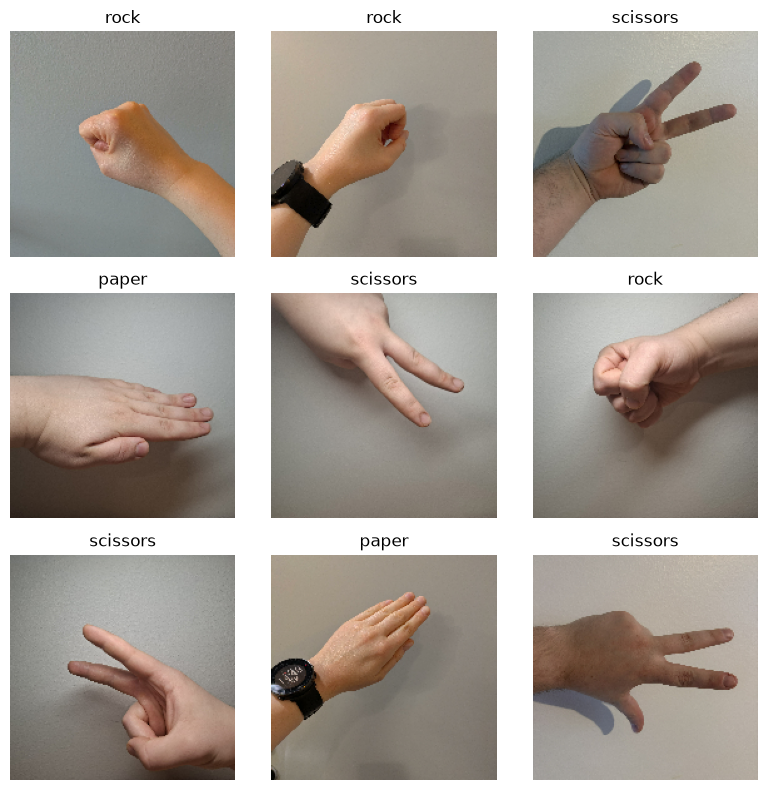

In [66]:
class_names = train_dataset.class_names
print("Classes:", class_names)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

This shows 9 images from the training dataset with their class names. The images are displayed in a 3×3 grid. Each image has a label showing if it is paper, rock or scissors. This helps to check that the images are loaded correctly and have the correct labels.

In [67]:
def normalize(images, labels):
    return images / 255.0, labels

train_ds = train_dataset.map(normalize)
val_ds = validation_dataset.map(normalize)
test_ds = test_dataset.map(normalize)

This changes image pixel values from 0–255 to 0–1. This helps the model learn better.

<h2>4. Modeling</h2>

 - Three versions of a convolutional neural network (CNN) were developed to classify images into rock, paper, and scissors.
 - Different model configurations were tested to compare their performance.
 - Training and validation accuracy and loss were monitored to evaluate the models.

In [68]:
model_1_v1 = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(3, activation="softmax")
])

model_1_v1.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_21 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │     3,276,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,370,307 (12.86 MB)

 Trainable params: 3,370,307 (12.86 MB)

 Non-trainable params: 0 (0.00 B)

The first CNN model was created using Keras Sequential. The model takes images with a size of 180×180 pixels and uses three Conv2D layers with 32, 64 and 128 filters to find important features in the images. MaxPooling2D reduces the image size after each convolutional layer. Flatten and Dense layers are used to classify the images, while Dropout helps reduce overfitting. The final Dense layer has 3 outputs with softmax activation, one for each class: paper, rock and scissors. The model summary shows the structure and number of parameters.

In [69]:
model_1_v1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_1_v1 = model_1_v1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


C:\Users\artem\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.3927 - loss: 1.3113 - val_accuracy: 0.3396 - val_loss: 1.1012
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 675ms/step - accuracy: 0.3822 - loss: 1.1071 - val_accuracy: 0.3396 - val_loss: 1.1127
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.3298 - loss: 1.1022 - val_accuracy: 0.3396 - val_loss: 1.0991
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 927ms/step - accuracy: 0.3141 - loss: 1.1026 - val_accuracy: 0.3585 - val_loss: 1.0996
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 877ms/step - accuracy: 0.3508 - loss: 1.1037 - val_accuracy: 0.3396 - val_loss: 1.0981
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 981ms/step - accuracy: 0.3089 - loss: 1.1026 - val_accuracy: 0.3774 - val_loss: 1.0929
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 768ms/step - accuracy: 0.3927 - loss: 1.1036 - val_accuracy: 0.2453 - val_loss: 1.1045
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 730ms/step - accuracy: 0.3874 - loss: 1.0800 - val_accuracy: 0.3774 - val_loss: 1.1218
Epoch 9/

Training CNN Model 1

The first CNN model was trained using the Adam optimizer from Keras. Adam was chosen to help the model learn and reduce errors. The learning rate was set to 0.001. The loss function sparse_categorical_crossentropy was used because we have three classes: paper, rock and scissors. Accuracy shows how many images the model predicts correctly. The model was trained for 10 epochs. The validation dataset was used to check how well the model works with new images.

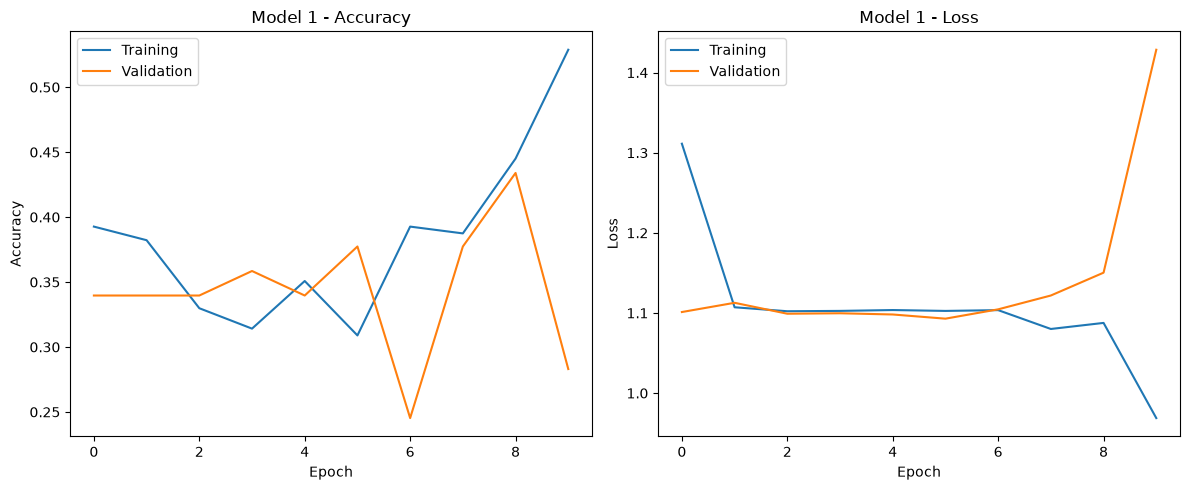

In [70]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_1_v1.history["accuracy"], label="Training")
plt.plot(history_1_v1.history["val_accuracy"], label="Validation")
plt.title("Model 1 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_1_v1.history["loss"], label="Training")
plt.plot(history_1_v1.history["val_loss"], label="Validation")
plt.title("Model 1 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

These graphs show how the first CNN model performed during training. The first graph shows accuracy, which tells us how many images were predicted correctly. The second graph shows loss, which tells us how many errors the model made. Both graphs compare training and validation results. This helps us see if the model is learning well or starting to overfit.

In [71]:
model_1_v2 = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(3, activation="softmax")
])

model_1_v2.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

For the second version, the model structure was changed to try to reduce overfitting. The model still uses three Conv2D layers with 32, 64 and 128 filters, followed by MaxPooling2D layers. The main difference is that Flatten was replaced with GlobalAveragePooling2D. This reduces the number of parameters and makes the model smaller. Dense and Dropout layers are also used, and the final layer has 3 outputs for paper, rock and scissors.

In [73]:
model_1_v2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=6,
    restore_best_weights=True
)

history_1_v2 = model_1_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.2723 - loss: 1.1122 - val_accuracy: 0.3396 - val_loss: 1.0989
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.3141 - loss: 1.1028 - val_accuracy: 0.3208 - val_loss: 1.1005
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.3246 - loss: 1.1010 - val_accuracy: 0.3208 - val_loss: 1.1006
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 566ms/step - accuracy: 0.3194 - loss: 1.0995 - val_accuracy: 0.3208 - val_loss: 1.0998
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 710ms/step - accuracy: 0.3089 - loss: 1.0992 - val_accuracy: 0.3208 - val_loss: 1.1006
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3560 - loss: 1.0981 - val_accuracy: 0.3208 - val_loss: 1.1028
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.3665 - loss: 1.0970 - val_accuracy: 0.3208 - val_loss: 1.1075


Training CNN Model 2
This time, EarlyStopping was added to stop training if the validation accuracy does not improve for 6 epochs. It also saves the best weights from training. The model was set to train for a maximum of 20 epochs. EarlyStopping helps avoid unnecessary training when the model stops improving.

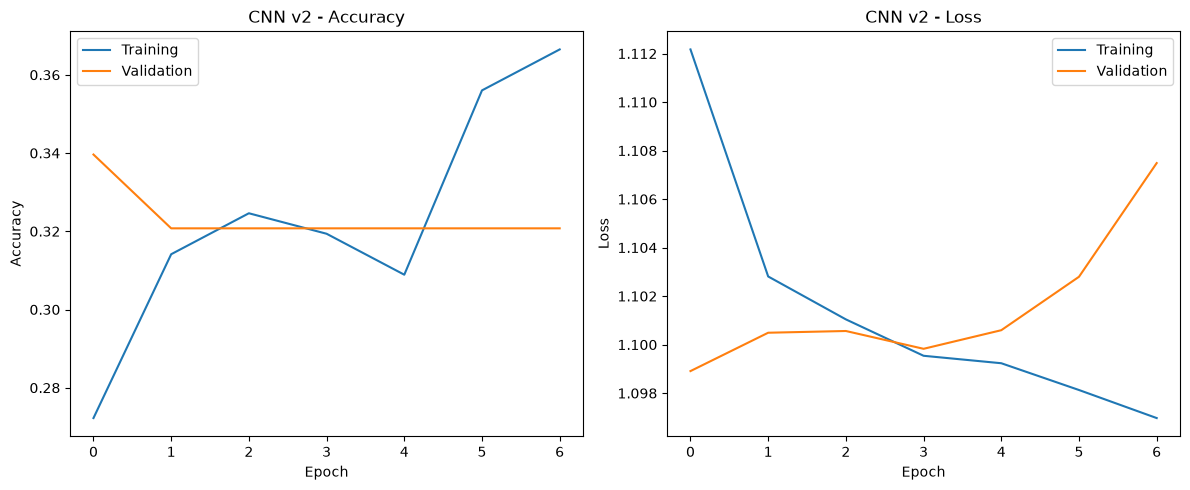

In [80]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_1_v2.history["accuracy"], label="Training")
plt.plot(history_1_v2.history["val_accuracy"], label="Validation")
plt.title("CNN v2 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_1_v2.history["loss"], label="Training")
plt.plot(history_1_v2.history["val_loss"], label="Validation")
plt.title("CNN v2 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

The results of the second CNN model are in the graphs.

In [87]:
model_1_v3_retry = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(3, activation="softmax")
])

model_1_v3_retry.summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 178, 178, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 89, 89, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 87, 87, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_36 (MaxPooling2D) │ (None, 43, 43, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 41, 41, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_37 (MaxPooling2D) │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 32)             │       819,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 842,915 (3.22 MB)

 Trainable params: 842,915 (3.22 MB)

 Non-trainable params: 0 (0.00 B)

In the third version, the number of filters was reduced to 16, 32 and 64. The model uses Flatten and Dense layers, and Dropout was reduced to 0.2. These changes were made to help the model learn better and reduce overfitting.

In [88]:
model_1_v3_retry.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [89]:
history_1_v3_retry = model_1_v3_retry.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 523ms/step - accuracy: 0.3560 - loss: 1.1899 - val_accuracy: 0.3585 - val_loss: 1.0974
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 379ms/step - accuracy: 0.3560 - loss: 1.0961 - val_accuracy: 0.3396 - val_loss: 1.0971
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 377ms/step - accuracy: 0.3351 - loss: 1.0970 - val_accuracy: 0.3396 - val_loss: 1.0967
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 385ms/step - accuracy: 0.4188 - loss: 1.0957 - val_accuracy: 0.3019 - val_loss: 1.0956
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 386ms/step - accuracy: 0.3822 - loss: 1.0859 - val_accuracy: 0.3396 - val_loss: 1.0995
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 377ms/step - accuracy: 0.3194 - loss: 1.0895 - val_accuracy: 0.3396 - val_loss: 1.1000
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 388ms/step - accuracy: 0.3822 - loss: 1.0845 - val_accuracy: 0.3396 - val_loss: 1.1023
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 455ms/step - accuracy: 0.3560 - loss: 1.0753 - val_accuracy: 0.3396 - val_loss:

The model was trained for 20 epochs using the training dataset. The validation dataset was used to check how well the model performs on new images. This time, EarlyStopping was not used, so the model completed all 20 epochs.

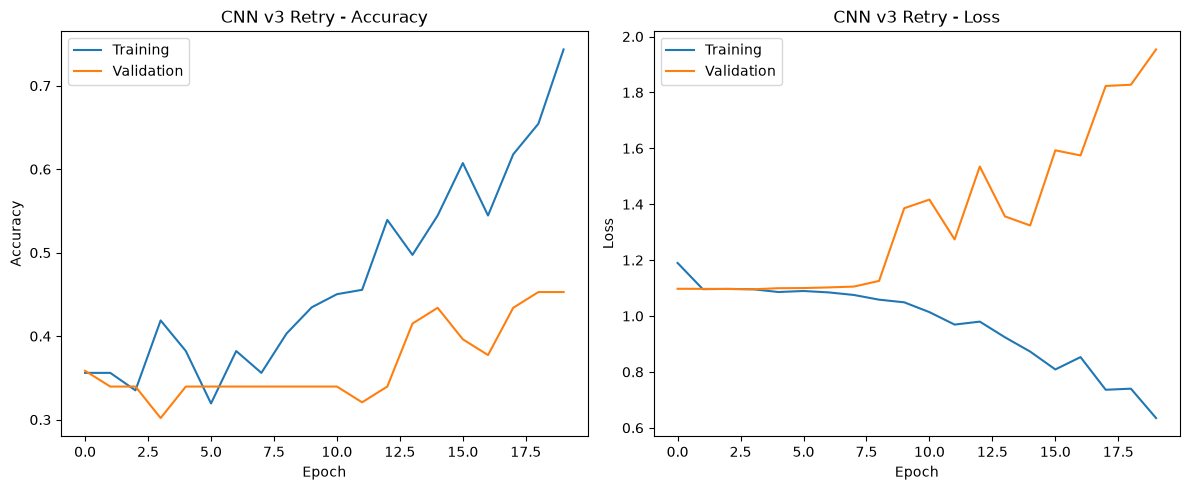

In [90]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_1_v3_retry.history["accuracy"], label="Training")
plt.plot(history_1_v3_retry.history["val_accuracy"], label="Validation")
plt.title("CNN v3 Retry - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_1_v3_retry.history["loss"], label="Training")
plt.plot(history_1_v3_retry.history["val_loss"], label="Validation")
plt.title("CNN v3 Retry - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

The results of the third CNN model are in the graphs.

In [92]:
models = [
    ("CNN v1", model_1_v1),
    ("CNN v2", model_1_v2),
    ("CNN v3", model_1_v3_retry)
]

for name, model in models:
    loss, accuracy = model.evaluate(val_ds, verbose=0)

    print(name)
    print(f"Validation accuracy: {accuracy:.2%}")
    print(f"Validation loss: {loss:.4f}")
    print()

CNN v1
Validation accuracy: 28.30%
Validation loss: 1.4285

CNN v2
Validation accuracy: 33.96%
Validation loss: 1.0989

CNN v3
Validation accuracy: 45.28%
Validation loss: 1.9538



All three CNN models were compared using the validation dataset. The first model achieved 28.30% accuracy, the second 33.96% and the third 45.28%. The third version had the highest validation accuracy, but its loss was also the highest. This shows that the model still has problems with overfitting.

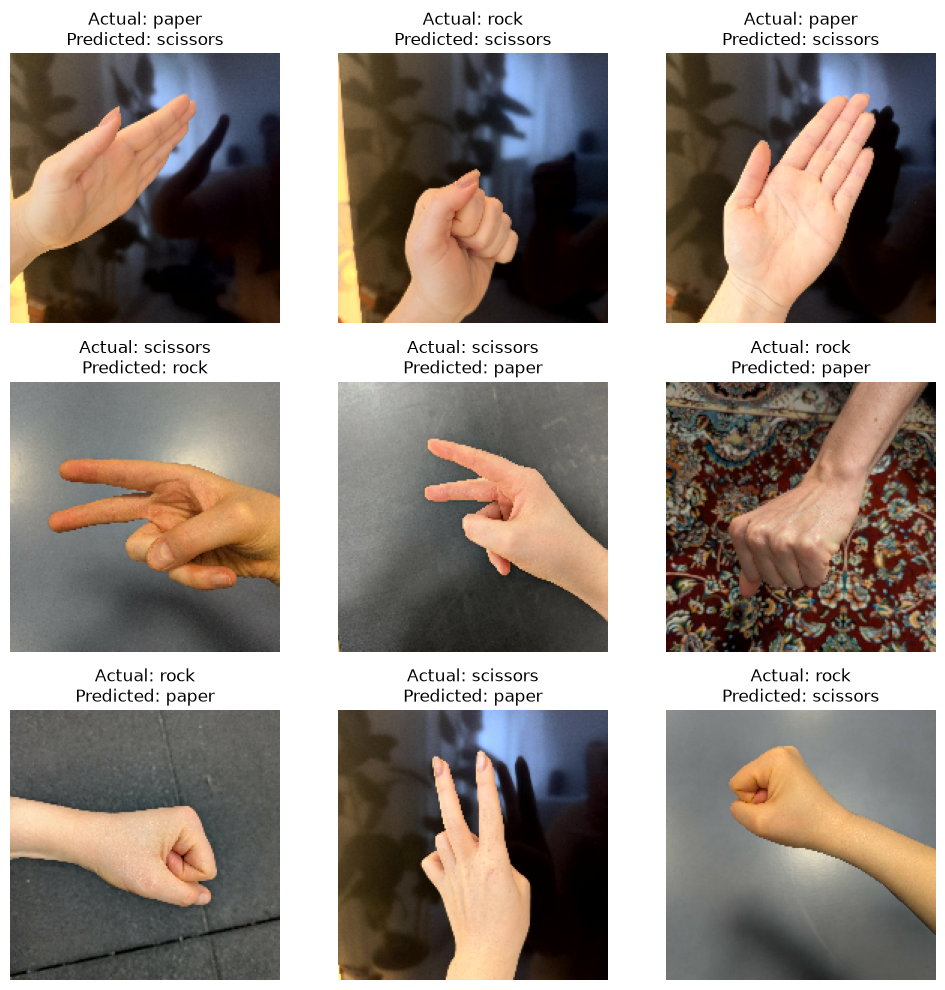

In [93]:
wrong_images = []

for images, labels in val_ds:
    predictions = model_1_v3_retry.predict(images, verbose=0)
    predicted_labels = tf.argmax(predictions, axis=1).numpy()

    for image, actual, predicted in zip(images, labels.numpy(), predicted_labels):
        if actual != predicted:
            wrong_images.append((image.numpy(), actual, predicted))

plt.figure(figsize=(10, 10))

for i, (image, actual, predicted) in enumerate(wrong_images[:9]):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(f"Actual: {class_names[actual]}\nPredicted: {class_names[predicted]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

The third CNN model was used to check incorrectly predicted images. The code shows 9 images where the model made mistakes. Each image shows the correct class and the class predicted by the model. This helps us see which images the model has problems recognizing.

In [94]:
test_loss, test_accuracy = model_1_v3_retry.evaluate(test_ds)

print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 196ms/step - accuracy: 0.3774 - loss: 1.9397
Test accuracy: 37.74%
Test loss: 1.9397


The third CNN model was tested using the test dataset. The model achieved 37.74% test accuracy and 1.9397 test loss. These results show that the model still has problems recognizing new images. The accuracy is quite low, even though the model learned better on the training dataset.

<h2>5. Evaluation</h2>

Three versions of a CNN model were created and tested to recognize rock, paper and scissors images. Different layers and settings were used to compare the results. The third version achieved the highest validation accuracy of 45.28%. The final model was tested using test images and achieved an accuracy of 37.74%. The results showed that the model learned the training images better than new images. This indicates overfitting. The model did not achieve good accuracy, but the tests helped to understand how different settings affect the results. More training images and further improvements could help improve the accuracy.

<h2>6. Deployment</h2>

The CNN model was created to recognize rock, paper and scissors images. The final model achieved 37.74% accuracy on the test dataset. This result is too low for real-world use, because the model still makes many mistakes. For future development, more training images with different backgrounds and lighting could be added. Data augmentation and further changes to the model could also help improve accuracy. The model should be tested again with new images before it can be used in practice.